# SpaVista spatial gene expression demo: cSCC-HVG fold 0

This notebook evaluates the released fold-0 prediction head on three held-out cSCC slides. It performs inference and evaluation only. Follow the installation and checkpoint-download instructions in the [repository README](../../README.md), select the `SpaVista` kernel, and run the cells in order.


In [4]:
from pathlib import Path
import sys

repo_root = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / 'demo' / 'sge_fold0' / 'run_demo.py').is_file()),
    None,
)
if repo_root is None:
    raise FileNotFoundError('Start Jupyter from the SpaVista repository or one of its subdirectories.')

DEVICE_NUM = 0
BATCH_SIZE = 16
print('SpaVista repository detected.')
print(f'CUDA device index: {DEVICE_NUM}')


SpaVista repository detected.
CUDA device index: 0


In [5]:
import subprocess

completed = subprocess.run(
    [sys.executable, str(repo_root / 'demo' / 'sge_fold0' / 'run_demo.py'),
     '--device-num', str(DEVICE_NUM), '--batch-size', str(BATCH_SIZE)],
    cwd=repo_root,
    stdout=subprocess.PIPE,
    stderr=subprocess.PIPE,
    text=True,
)
if completed.returncode != 0:
    raise RuntimeError('Demo failed. Run demo/sge_fold0/run_demo.py from a terminal to inspect the full log.')
print('Fold-0 inference and evaluation complete.')


Fold-0 inference and evaluation complete.


,slice_idx,medpcc_gene,med_spearman_gene
0,0,0.3140,0.3074
1,1,0.3209,0.3159
2,2,0.3375,0.3273


Median gene PCC: 0.3209
Median gene SCC: 0.3159


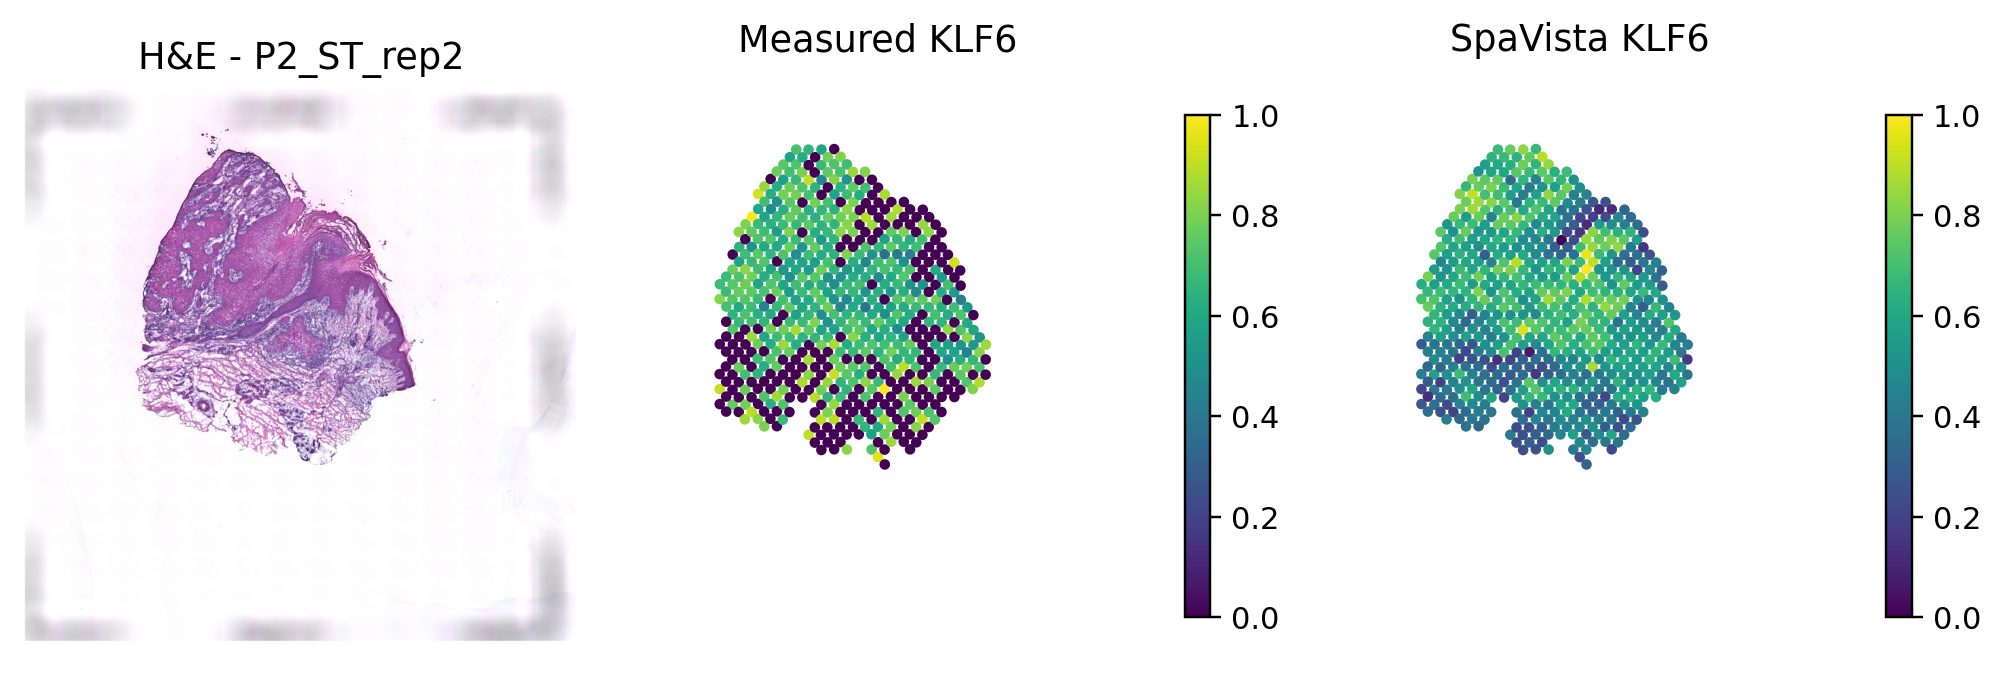

In [6]:
import pandas as pd
from IPython.display import Image, display

output_dir = repo_root / 'results' / 'demo' / 'cscc_hvg_fold0'
metrics = pd.read_csv(output_dir / 'median_performance_metrics.csv')
display(metrics[['slice_idx', 'medpcc_gene', 'med_spearman_gene']].round(4))
print(f"Median gene PCC: {metrics['medpcc_gene'].median():.4f}")
print(f"Median gene SCC: {metrics['med_spearman_gene'].median():.4f}")
display(Image(filename=str(output_dir / 'figures' / 'P2_ST_rep2_KLF6.png'), width=800))